<a target="_blank" href="https://colab.research.google.com/github/taobrienlbl/advanced_earth_science_data_analysis/blob/fall_2025_iub/content/lessons/02_modules_vscode_git/02_last_class_refresher.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

# Warmup: fundamentals

Recall that last week's objectives were:

* Describe fundamental aspects of a working Python script
* Implement novel functions and for loops along with appropriate unit tests
* Utilize 'external' python packages

This warm-up aims to build on those objectives and reinforce them.


## 1. Basics of functions

### 1(a): ins and outs

Run the following cell.  It doesn't work as expected.  Explain why (in a markdown cell below it) and create a new cell below that with a fixed version of the code.

In [1]:
def factorial(n):
    """Calculates the factorial of a number."""
    fac = 1
    if n == 1:
        fac = 1
    else:
        fac = n * factorial(n-1)


# test the factorial function; this should print 120
print(factorial(5))

TypeError: unsupported operand type(s) for *: 'int' and 'NoneType'

The function doesn't return any value, therefore making the function return a value of None. Since you are calling the function again in the same code without returning any values, then you will have an int * None, which is the error. Also, the fac variable is not needed because you return.

In [2]:
def factorial(n):
    """Calculates the factorial of a number."""
    if n == 1:
        return 1
    else:
        return n * factorial(n-1)


# test the factorial function; this should print 120
print(factorial(5))

120


### 1(b): Writing new functions

Write a function representing the formula $z = x^2 + y^2$ and verify that it works as expected.

In [3]:
def z_formula(x,y):
    z = (x)**2 + (y)**2
    return z

print(z_formula(-1,1))

2


### 1(c): Scope

We haven't yet discussed the concept of *scope*, so we'll introduce it here through examining an interesting effect (and we'll discuss it more as time goes on.)

Run the cell below.  We see that the value of `a` is redefined when `redefine_and_print_a()` is called, so why does the last print statement contain the original definition of `a` and not the one it was given within the function?


In [4]:
# define a as a global variable here
a = "This is `a` with global scope."
# print a to show its value
print(f"1: {a}")

# define a function
def redefine_and_print_a():
    # define a as a local variable here
    a = "This is `a` with local scope."
    # print a to show its value
    print(f"2: {a}")

# call the function
redefine_and_print_a()

# print a one more time to show its value
print(f"3: {a}")



1: This is `a` with global scope.
2: This is `a` with local scope.
3: This is `a` with global scope.


It contains the original definition of a because the local definition only exists within the scope of the function. You didn't redefine a outside of the function (for example, a = redefine_and_print_a), so it does not apply globally to the code.

## 2. Using external packages

Make a plot of the following equation  using `numpy` and `matplotlib`.  Use `x` values ranging from -8 to 8, and make plots using the following values of $\sigma$: $\sigma = [0.25,0.5,1,2,4]$

$$N(x) = \frac{1}{\sigma \sqrt{2 \pi}} e^{-\frac{x^2}{2 \sigma^2}}$$

Your solution should (a) define a new function to represent this formula, and (b) use a `for` loop.

If you have time, customize the x- and y-axis labels, and add a legend.

Text(0, 0.5, 'Values of N(x)')

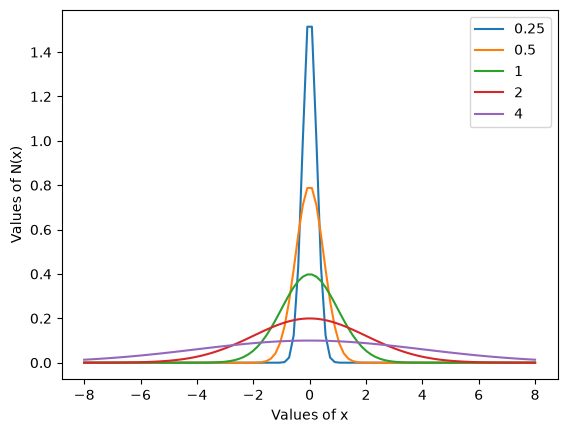

In [5]:
import numpy as np
import matplotlib.pyplot as plt

#Create the values of x and the list of sigma values
x_values = np.linspace(-8, 8, 100)
sigma_values = [0.25, 0.5, 1, 2, 4]

#Defining the function to return the value of the equation
def N_function(x, sigma):
    """
    Values in: int x for the x value, float sigma for the sigma value
    Value out: float that's the answer to the equation given above
    
    Calculates the value of N(x) above when given a specific x value and specific sigma value
    """

    #For less coding errors, I split up the coefficient and the exponent as two different calculations
    
    coefficient = 1/(sigma*np.sqrt(2*np.pi))
    
    exponent = np.exp(-(x**2)/(2*(sigma**2)))
    
    #Multiplying the coefficient and the exponent together and returning the value
    return coefficient * exponent
    
#To plot all of the sigma values, we have to run a for loop of all of the sigma values in the sigma_values list while running through the x_values list to create the curve for our y values.
for sigma in sigma_values:
    y_values = N_function(x_values, sigma)
    plt.plot(x_values, y_values, label = sigma)
    
plt.legend()
plt.xlabel("Values of x")
plt.ylabel("Values of N(x)")
